<center><h2> Spatial redistribution of a globally constant marine biological carbon pump </h2></center>
    
<center><h3> Figures and statistics </h3></center>

**L. Delaigue<sup>1, 2</sup>\, R. Sauzède<sup>3</sup>, O. Sulpis<sup>4</sup>, P. W. Boyd<sup>5</sup>, H. Claustre<sup>2</sup>, G-J Reichart<sup>1, 6</sup> and M. P. Humphreys<sup>1</sup>**

<sup>1</sup>Department of Ocean Systems (OCS), NIOZ Royal Netherlands Institute for Sea Research, PO Box 59, 1790 AB Den Burg (Texel), the Netherlands

<sup>2</sup>Sorbonne Université, CNRS, Laboratoire d’Océanographie de Villefranche, Villefranche-Sur-Mer, France

<sup>3</sup>Sorbonne Université, CNRS, Institut de la Mer de Villefranche, Villefranche-Sur-Mer, France

<sup>4</sup>CEREGE, Aix Marseille Univ, CNRS, IRD, INRAE, Collège de France, Aix-en-Provence, France

<sup>5</sup>Institute for Marine and Antarctic Studies, University of Tasmania, Hobart, Tasmania, Australia

<sup>6</sup>Department of Earth Sciences, Utrecht University, Utrecht, the Netherlands

## Abstract

Marine dissolved inorganic carbon (DIC) is a key component of the global ocean carbon cycle. Over recent decades, DIC has increased due to rising anthropogenic CO<sub>2</sub>, but the component of DIC change due to the biological carbon pump (BCP), which transfers carbon from the surface to the deep ocean, remains highly uncertain. Using the GOBAI-O<sub>2</sub> data product and the CANYON-B and CONTENT algorithms, we reconstructed the 3-dimensional global DIC<sub>total</sub> distribution from 2004 to 2022 and decomposed it into DIC<sub>soft</sub> (resulting from organic matter degradation), DIC<sub>carb</sub> (resulting from carbonate dissolution), and DIC<sub>anth</sub> (anthropogenic CO<sub>2</sub> plus changes in air-sea disequilibrium). We found a significant DIC<sub>total</sub> change throughout the water column, with surface concentrations increasing by ~1.0 ± 0.23 μmol kg<sup>-1</sup> yr<sup>-1</sup>, driven by DIC<sub>anth</sub> (>90% contribution). Despite a globally constant signal in DIC<sub>soft</sub>, substantial regional trends emerged. Changes in circulation, particle sinking, and remineralization altered the vertical and horizontal distributions of DIC<sub>soft</sub>. In some regions, DIC<sub>soft</sub> accumulated at shallower depths, shortening residence times; in others, it was transported deeper, enhancing long-term storage. Although these widespread and divergent trends had little net effect on the global DIC<sub>soft</sub> inventory from 2004-2022, the emerging spatial reorganization of the BCP may signal an evolving instability in the ocean carbon sink under continued climate forcing.

**____________________________________________________________________________________________________________________________**


In [23]:
import matplotlib.pyplot as plt
import xarray as xr

import warnings
warnings.filterwarnings('ignore')

# Load dataset
ds = xr.load_dataset("data/CONTENT_DIC_v2-1.nc")



In [8]:
ds

<xarray.Dataset> Size: 19GB
Dimensions:       (lon: 360, lat: 145, pres: 58, time: 228)
Coordinates:
  * lon           (lon) float32 1kB -179.5 -178.5 -177.5 ... 177.5 178.5 179.5
  * lat           (lat) float32 580B -64.5 -63.5 -62.5 -61.5 ... 77.5 78.5 79.5
  * pres          (pres) float32 232B 2.5 10.0 20.0 ... 1.9e+03 1.975e+03
  * time          (time) datetime64[ns] 2kB 2004-01-15 2004-02-15 ... 2022-12-15
Data variables:
    oxy           (time, pres, lat, lon) float32 3GB 346.1 347.6 ... nan nan
    temp          (time, pres, lat, lon) float32 3GB 1.527 1.505 ... nan nan
    sal           (time, pres, lat, lon) float32 3GB 33.82 33.81 ... nan nan
    uncer         (time, pres, lat, lon) float32 3GB 12.15 12.15 ... nan nan
    CT            (time, lon, lat, pres) float32 3GB 2.138e+03 2.138e+03 ... nan
    CT_sigma      (time, lon, lat, pres) float32 3GB 11.62 11.6 ... nan nan
    CT_sigma_min  (time, lon, lat, pres) float32 3GB 9.182 9.112 9.0 ... nan nan

In [9]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import gsw


In [10]:
def n2_mean_0_200_profile(sp, t, p, lon, lat):
    """
    sp, t: 1D arrays over pres
    p:  1D pressure (dbar)
    lon, lat: scalars
    returns: thickness-weighted mean N^2 over midpoints <= 200 dbar
    """
    # guard against all-NaN profiles
    if np.all(np.isnan(sp)) or np.all(np.isnan(t)):
        return np.nan
    
    # TEOS-10 conversions
    SA = gsw.SA_from_SP(sp, p, lon, lat)      # Absolute Salinity
    CT = gsw.CT_from_t(SA, t, p)              # Conservative Temperature
    
    # N^2 is defined on midpoints between pressure levels
    N2, p_mid = gsw.Nsquared(SA, CT, p, lat)  # N2: length pres-1
    
    # thickness weights in pressure coordinates (fine for layer-mean mapping)
    dp = np.diff(p)  # length pres-1
    
    mask = np.isfinite(N2) & (p_mid <= 200.0) & np.isfinite(dp)
    if np.sum(mask) == 0:
        return np.nan
    
    return np.nansum(N2[mask] * dp[mask]) / np.nansum(dp[mask])


In [11]:
# Ensure the variables you use have consistent dimension order
temp = ds['temp'].transpose('time', 'pres', 'lat', 'lon')
sal  = ds['sal'].transpose('time', 'pres', 'lat', 'lon')
pres = ds['pres']
lon  = ds['lon']
lat  = ds['lat']

N2bar_0_200 = xr.apply_ufunc(
    n2_mean_0_200_profile,
    sal, temp, pres, lon, lat,
    input_core_dims=[['pres'], ['pres'], ['pres'], [], []],
    output_core_dims=[[]],
    vectorize=True,
    dask='allowed',              # works even without dask; if dask present, can parallelize
    output_dtypes=[np.float64],
)

N2bar_0_200.name = "N2bar_0_200"


<xarray.DataArray 'N2bar_0_200' (time: 228, lat: 145, lon: 360)> Size: 95MB
array([[[2.52829918e-05, 2.50675730e-05, 2.53062036e-05, ...,
         2.89148122e-05, 2.73773805e-05, 2.61888557e-05],
        [2.24457819e-05, 2.13538979e-05, 2.12055494e-05, ...,
         3.41352384e-05, 3.00974624e-05, 2.53971382e-05],
        [1.84038936e-05, 1.71523637e-05, 1.68056138e-05, ...,
         2.73882172e-05, 2.39579376e-05, 2.06818867e-05],
        ...,
        [           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        [           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        [           nan,            nan,            nan, ...,
                    nan,            nan,            nan]],

       [[2.88473378e-05, 2.79390454e-05, 2.79518122e-05, ...,
         3.88377586e-05, 3.51052085e-05, 3.12077128e-05],
        [2.34423681e-05, 2.28437593e-05, 2.32382682e-05, ...,
         3.09458850e-05, 2.77982606e-05, 2.52123175e-05],
        [1.93049760e-05, 1.87078567e-05, 1.89278664e-05, ...,
         2.24623275e-05, 2.13770577e-05, 2.02739870e-05],
...
                    nan,            nan,            nan],
        [           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        [           nan,            nan,            nan, ...,
                    nan,            nan,            nan]],

       [[2.11944250e-05, 2.17974575e-05, 2.23960177e-05, ...,
         1.98545212e-05, 2.02268380e-05, 2.07937581e-05],
        [1.71266795e-05, 1.63483819e-05, 1.60377817e-05, ...,
         1.60931337e-05, 1.67284180e-05, 1.73738772e-05],
        [1.19297201e-05, 1.00951733e-05, 8.92542700e-06, ...,
         1.11967543e-05, 1.22851149e-05, 1.27748263e-05],
        ...,
        [           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        [           nan,            nan,            nan, ...,
                    nan,            nan,            nan],
        [           nan,            nan,            nan, ...,
                    nan,            nan,            nan]]],
      shape=(228, 145, 360))
Coordinates:
  * lon      (lon) float32 1kB -179.5 -178.5 -177.5 -176.5 ... 177.5 178.5 179.5
  * lat      (lat) float32 580B -64.5 -63.5 -62.5 -61.5 ... 76.5 77.5 78.5 79.5
  * time     (time) datetime64[ns] 2kB 2004-01-15 2004-02-15 ... 2022-12-15

In [12]:
N2_annual = N2bar_0_200.groupby('time.year').mean('time', skipna=True)

# Trend: polyfit on the 'year' axis
fit = N2_annual.polyfit(dim='year', deg=1, skipna=True)
slope = fit['polyfit_coefficients'].sel(degree=1)
intercept = fit['polyfit_coefficients'].sel(degree=0)

slope.name = "dN2bar_dt_0_200"


<xarray.DataArray 'dN2bar_dt_0_200' (lat: 145, lon: 360)> Size: 418kB
array([[-7.78441458e-08, -9.59011754e-08, -1.10956073e-07, ...,
        -8.63966677e-08, -7.24338414e-08, -6.76331190e-08],
       [-4.77846567e-08, -6.57028209e-08, -8.33123492e-08, ...,
        -7.43525789e-08, -5.06885049e-08, -4.04503845e-08],
       [-1.88941724e-08, -1.97503982e-08, -1.91610141e-08, ...,
        -3.33673679e-08, -2.13460226e-08, -1.74742213e-08],
       ...,
       [            nan,             nan,             nan, ...,
                    nan,             nan,             nan],
       [            nan,             nan,             nan, ...,
                    nan,             nan,             nan],
       [            nan,             nan,             nan, ...,
                    nan,             nan,             nan]],
      shape=(145, 360))
Coordinates:
    degree   int64 8B 1
  * lat      (lat) float32 580B -64.5 -63.5 -62.5 -61.5 ... 76.5 77.5 78.5 79.5
  * lon      (lon) float32 1kB -179.5 -178.5 -177.5 -176.5 ... 177.5 178.5 179.5

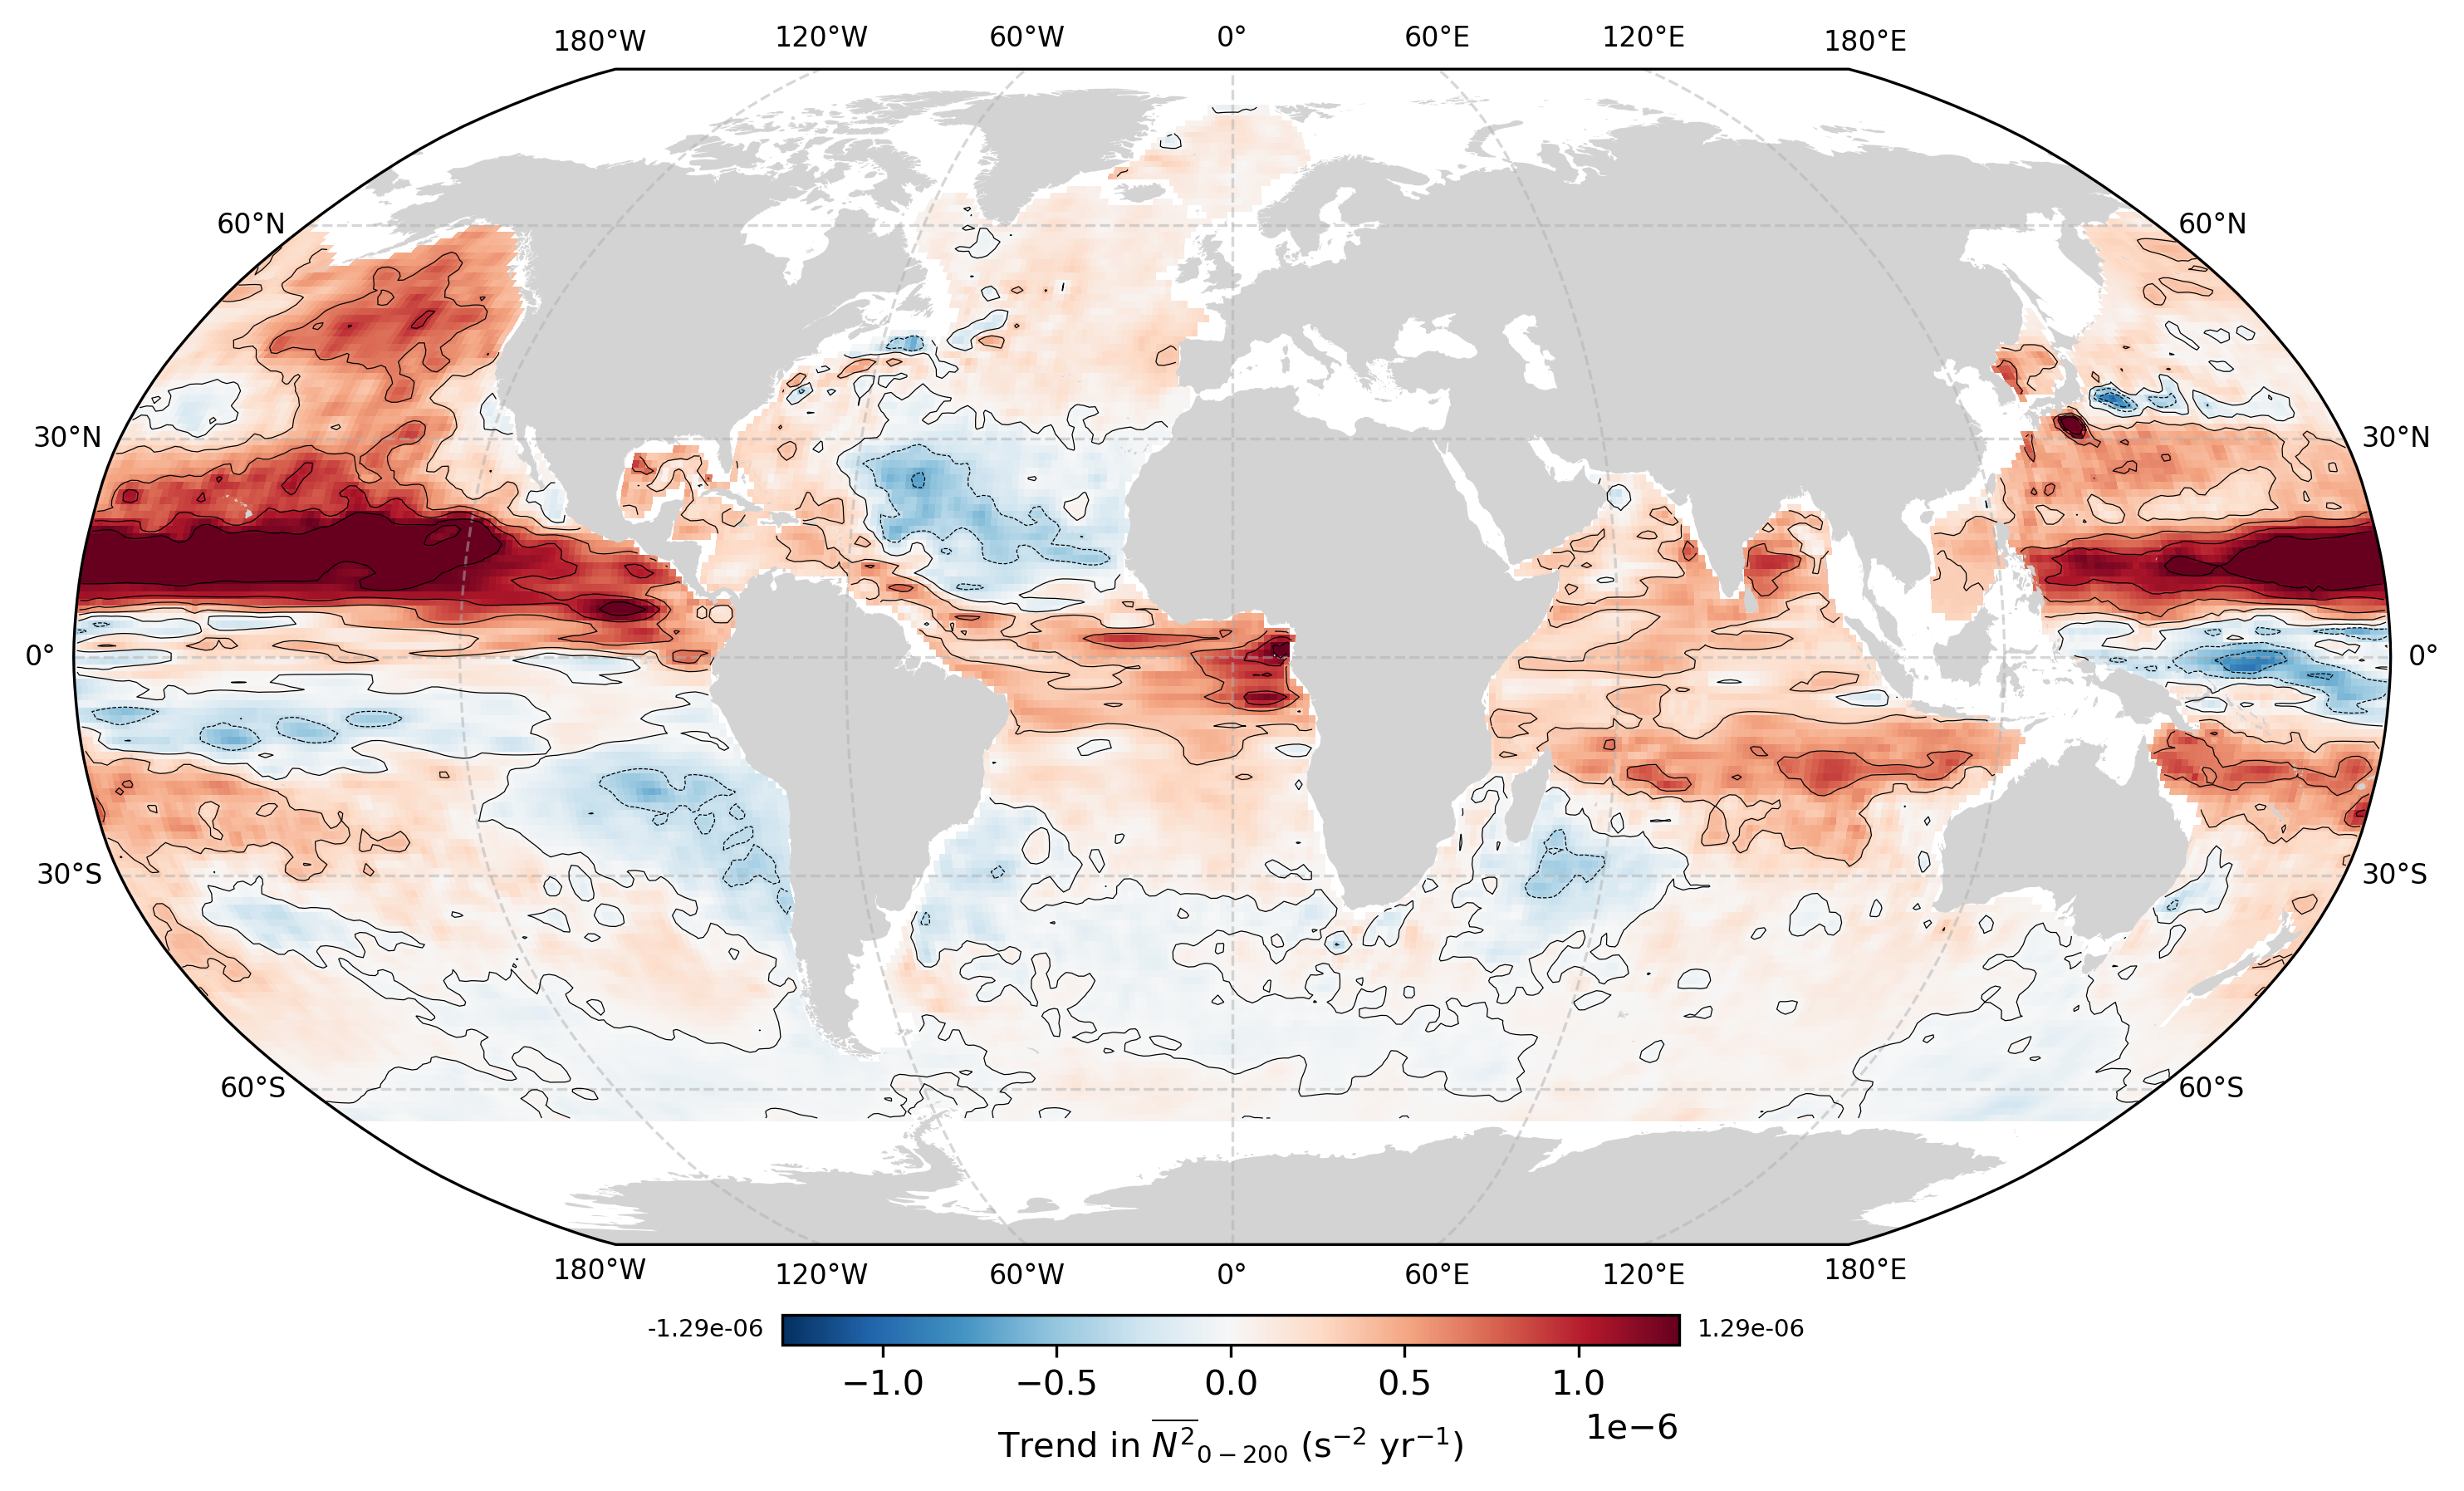

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.colors import TwoSlopeNorm
import matplotlib.ticker as mticker
import cartopy.mpl.ticker as cticker

# --- Define Mediterranean mask function ---
def mask_mediterranean(lat, lon):
    lat_min, lat_max = 30, 46
    lon_min, lon_max = -6, 37
    return (lat >= lat_min) & (lat <= lat_max) & (lon >= lon_min) & (lon <= lon_max)

# --- Extract coordinates from your slope DataArray ---
lon = slope['lon'].values
lat = slope['lat'].values
lon_2d, lat_2d = np.meshgrid(lon, lat)

# --- Extract data ---
slope_data = slope.values  # s^-2 per year

# --- Mask Mediterranean (optional; keep consistent with your other figs) ---
med_mask = mask_mediterranean(lat_2d, lon_2d)
slope_data = np.where(med_mask, np.nan, slope_data)

# --- Choose robust color limits (recommended for N² trends) ---
valid = np.isfinite(slope_data)
vmin = np.nanpercentile(slope_data[valid], 2)
vmax = np.nanpercentile(slope_data[valid], 98)

# Make symmetric around zero for TwoSlopeNorm
lim = max(abs(vmin), abs(vmax))
vmin, vmax = -lim, lim

# --- Create figure ---
fig = plt.figure(figsize=(12, 8), dpi=300)
ax1 = fig.add_subplot(1, 1, 1, projection=ccrs.Robinson())
ax1.set_global()

# Add land
land_feature = cfeature.NaturalEarthFeature('physical', 'land', '50m',
                                            edgecolor='none', facecolor='lightgrey')
ax1.add_feature(land_feature)

# --- Gridlines with formatting ---
gl = ax1.gridlines(draw_labels=True, alpha=0.5, linestyle='--')
gl.top_labels = True
gl.bottom_labels = True
gl.right_labels = True
gl.left_labels = True

gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
gl.ylocator = mticker.FixedLocator(np.arange(-90, 91, 30))

class CustomLongitudeFormatter(cticker.LongitudeFormatter):
    def __call__(self, lon, pos=None):
        if lon == 0:
            return "0°"
        elif lon < 0:
            return f"{abs(lon):g}°W"
        else:
            return f"{lon:g}°E"

gl.xformatter = CustomLongitudeFormatter()
gl.yformatter = cticker.LatitudeFormatter()

fig.canvas.draw()
for label in gl.xlabel_artists + gl.ylabel_artists:
    label.set_fontsize(8)

gl.xformatter._east_label = '180°E'

# --- Plot N² trend ---
norm1 = TwoSlopeNorm(vcenter=0, vmin=vmin, vmax=vmax)

im1 = ax1.pcolormesh(
    lon_2d, lat_2d, slope_data,
    transform=ccrs.PlateCarree(),
    cmap='RdBu_r',
    norm=norm1
)

# Optional: contour lines
# (Choose levels based on your symmetric limits)
levels = np.linspace(vmin, vmax, 9)
ax1.contour(
    lon_2d, lat_2d, slope_data,
    levels=levels, colors='black', linewidths=0.3,
    transform=ccrs.PlateCarree()
)

# --- Title and colorbar ---
ax1.set_title("")
cbar_ax1 = fig.add_axes([0.362, 0.15, 0.3, 0.015])
cbar1 = fig.colorbar(im1, cax=cbar_ax1, orientation='horizontal')
cbar1.set_label(r"Trend in $\overline{N^2}_{0-200}$ (s$^{-2}$ yr$^{-1}$)")

# Optional: end labels (use your actual min/max if you want)
cbar_ax1.text(-0.02, 0.5, f"{vmin:.2e}", va='center', ha='right',
              transform=cbar_ax1.transAxes, fontsize=7)
cbar_ax1.text(1.02, 0.5, f"{vmax:.2e}", va='center', ha='left',
              transform=cbar_ax1.transAxes, fontsize=7)

# --- Save ---
fig.savefig('figs/N2bar_0_200_trend_map.png', bbox_inches='tight', dpi=300)
plt.show()


In [24]:
import matplotlib.pyplot as plt
import xarray as xr

import warnings
warnings.filterwarnings('ignore')

# Load dataset
DICnat50 = xr.load_dataset("data/04_DIC_sequestered_50_depth_1000_iterations.nc")



In [25]:
import xarray as xr
import numpy as np
import gsw

z50 = DICnat50["DIC_nat_50_depth"]  # (time, lat, lon)

# Align z50 to ds grid in case there are minor coord differences
z50, ds_aligned = xr.align(z50, ds, join="inner")

# Use ds_aligned from now on
ds = ds_aligned


In [26]:
ds_aligned

<xarray.Dataset> Size: 19GB
Dimensions:       (lon: 360, lat: 145, pres: 58, time: 228)
Coordinates:
  * lon           (lon) float32 1kB -179.5 -178.5 -177.5 ... 177.5 178.5 179.5
  * lat           (lat) float32 580B -64.5 -63.5 -62.5 -61.5 ... 77.5 78.5 79.5
  * pres          (pres) float32 232B 2.5 10.0 20.0 ... 1.9e+03 1.975e+03
  * time          (time) datetime64[ns] 2kB 2004-01-15 2004-02-15 ... 2022-12-15
Data variables:
    oxy           (time, pres, lat, lon) float32 3GB 346.1 347.6 ... nan nan
    temp          (time, pres, lat, lon) float32 3GB 1.527 1.505 ... nan nan
    sal           (time, pres, lat, lon) float32 3GB 33.82 33.81 ... nan nan
    uncer         (time, pres, lat, lon) float32 3GB 12.15 12.15 ... nan nan
    CT            (time, lon, lat, pres) float32 3GB 2.138e+03 2.138e+03 ... nan
    CT_sigma      (time, lon, lat, pres) float32 3GB 11.62 11.6 ... nan nan
    CT_sigma_min  (time, lon, lat, pres) float32 3GB 9.182 9.112 9.0 ... nan nan

In [28]:
p = ds["pres"].values  # length 58
pres_mid_vals = 0.5 * (p[:-1] + p[1:])  # length 57

temp = ds["temp"].transpose("time","pres","lat","lon")
sal  = ds["sal"].transpose("time","pres","lat","lon")
pres = ds["pres"]
lon  = ds["lon"]
lat  = ds["lat"]

def n2_profile(sp, t, p, lon, lat):
    if np.all(np.isnan(sp)) or np.all(np.isnan(t)):
        return np.full((len(p)-1,), np.nan, dtype=np.float64)
    SA = gsw.SA_from_SP(sp, p, lon, lat)
    CT = gsw.CT_from_t(SA, t, p)
    N2, _ = gsw.Nsquared(SA, CT, p, lat)  # length len(p)-1
    return N2.astype(np.float64)

N2 = xr.apply_ufunc(
    n2_profile,
    sal, temp, pres, lon, lat,
    input_core_dims=[["pres"],["pres"],["pres"],[],[]],
    output_core_dims=[["pres_mid"]],
    output_sizes={"pres_mid": len(pres_mid_vals)},  # <-- key line
    vectorize=True,
    dask="allowed",
    output_dtypes=[np.float64],
)

# Assign coords cleanly
N2 = N2.assign_coords(pres_mid=("pres_mid", pres_mid_vals))
N2.name = "N2"


In [29]:
window = 100.0  # m ~ dbar

# Broadcast pres_mid to match (time, pres_mid, lat, lon)
P = N2["pres_mid"]

mask = (P >= (z50 - window)) & (P <= (z50 + window))
# xarray automatically broadcasts P (pres_mid) against z50 (time,lat,lon)

N2_z50band = N2.where(mask).mean("pres_mid", skipna=True)
N2_z50band.name = "N2_mean_z50pm100"


In [30]:
N2_z50band_annual = N2_z50band.groupby("time.year").mean("time", skipna=True)

fit = N2_z50band_annual.polyfit(dim="year", deg=1, skipna=True)
slope_z50band = fit["polyfit_coefficients"].sel(degree=1)
slope_z50band.name = "dN2_z50band_dt"


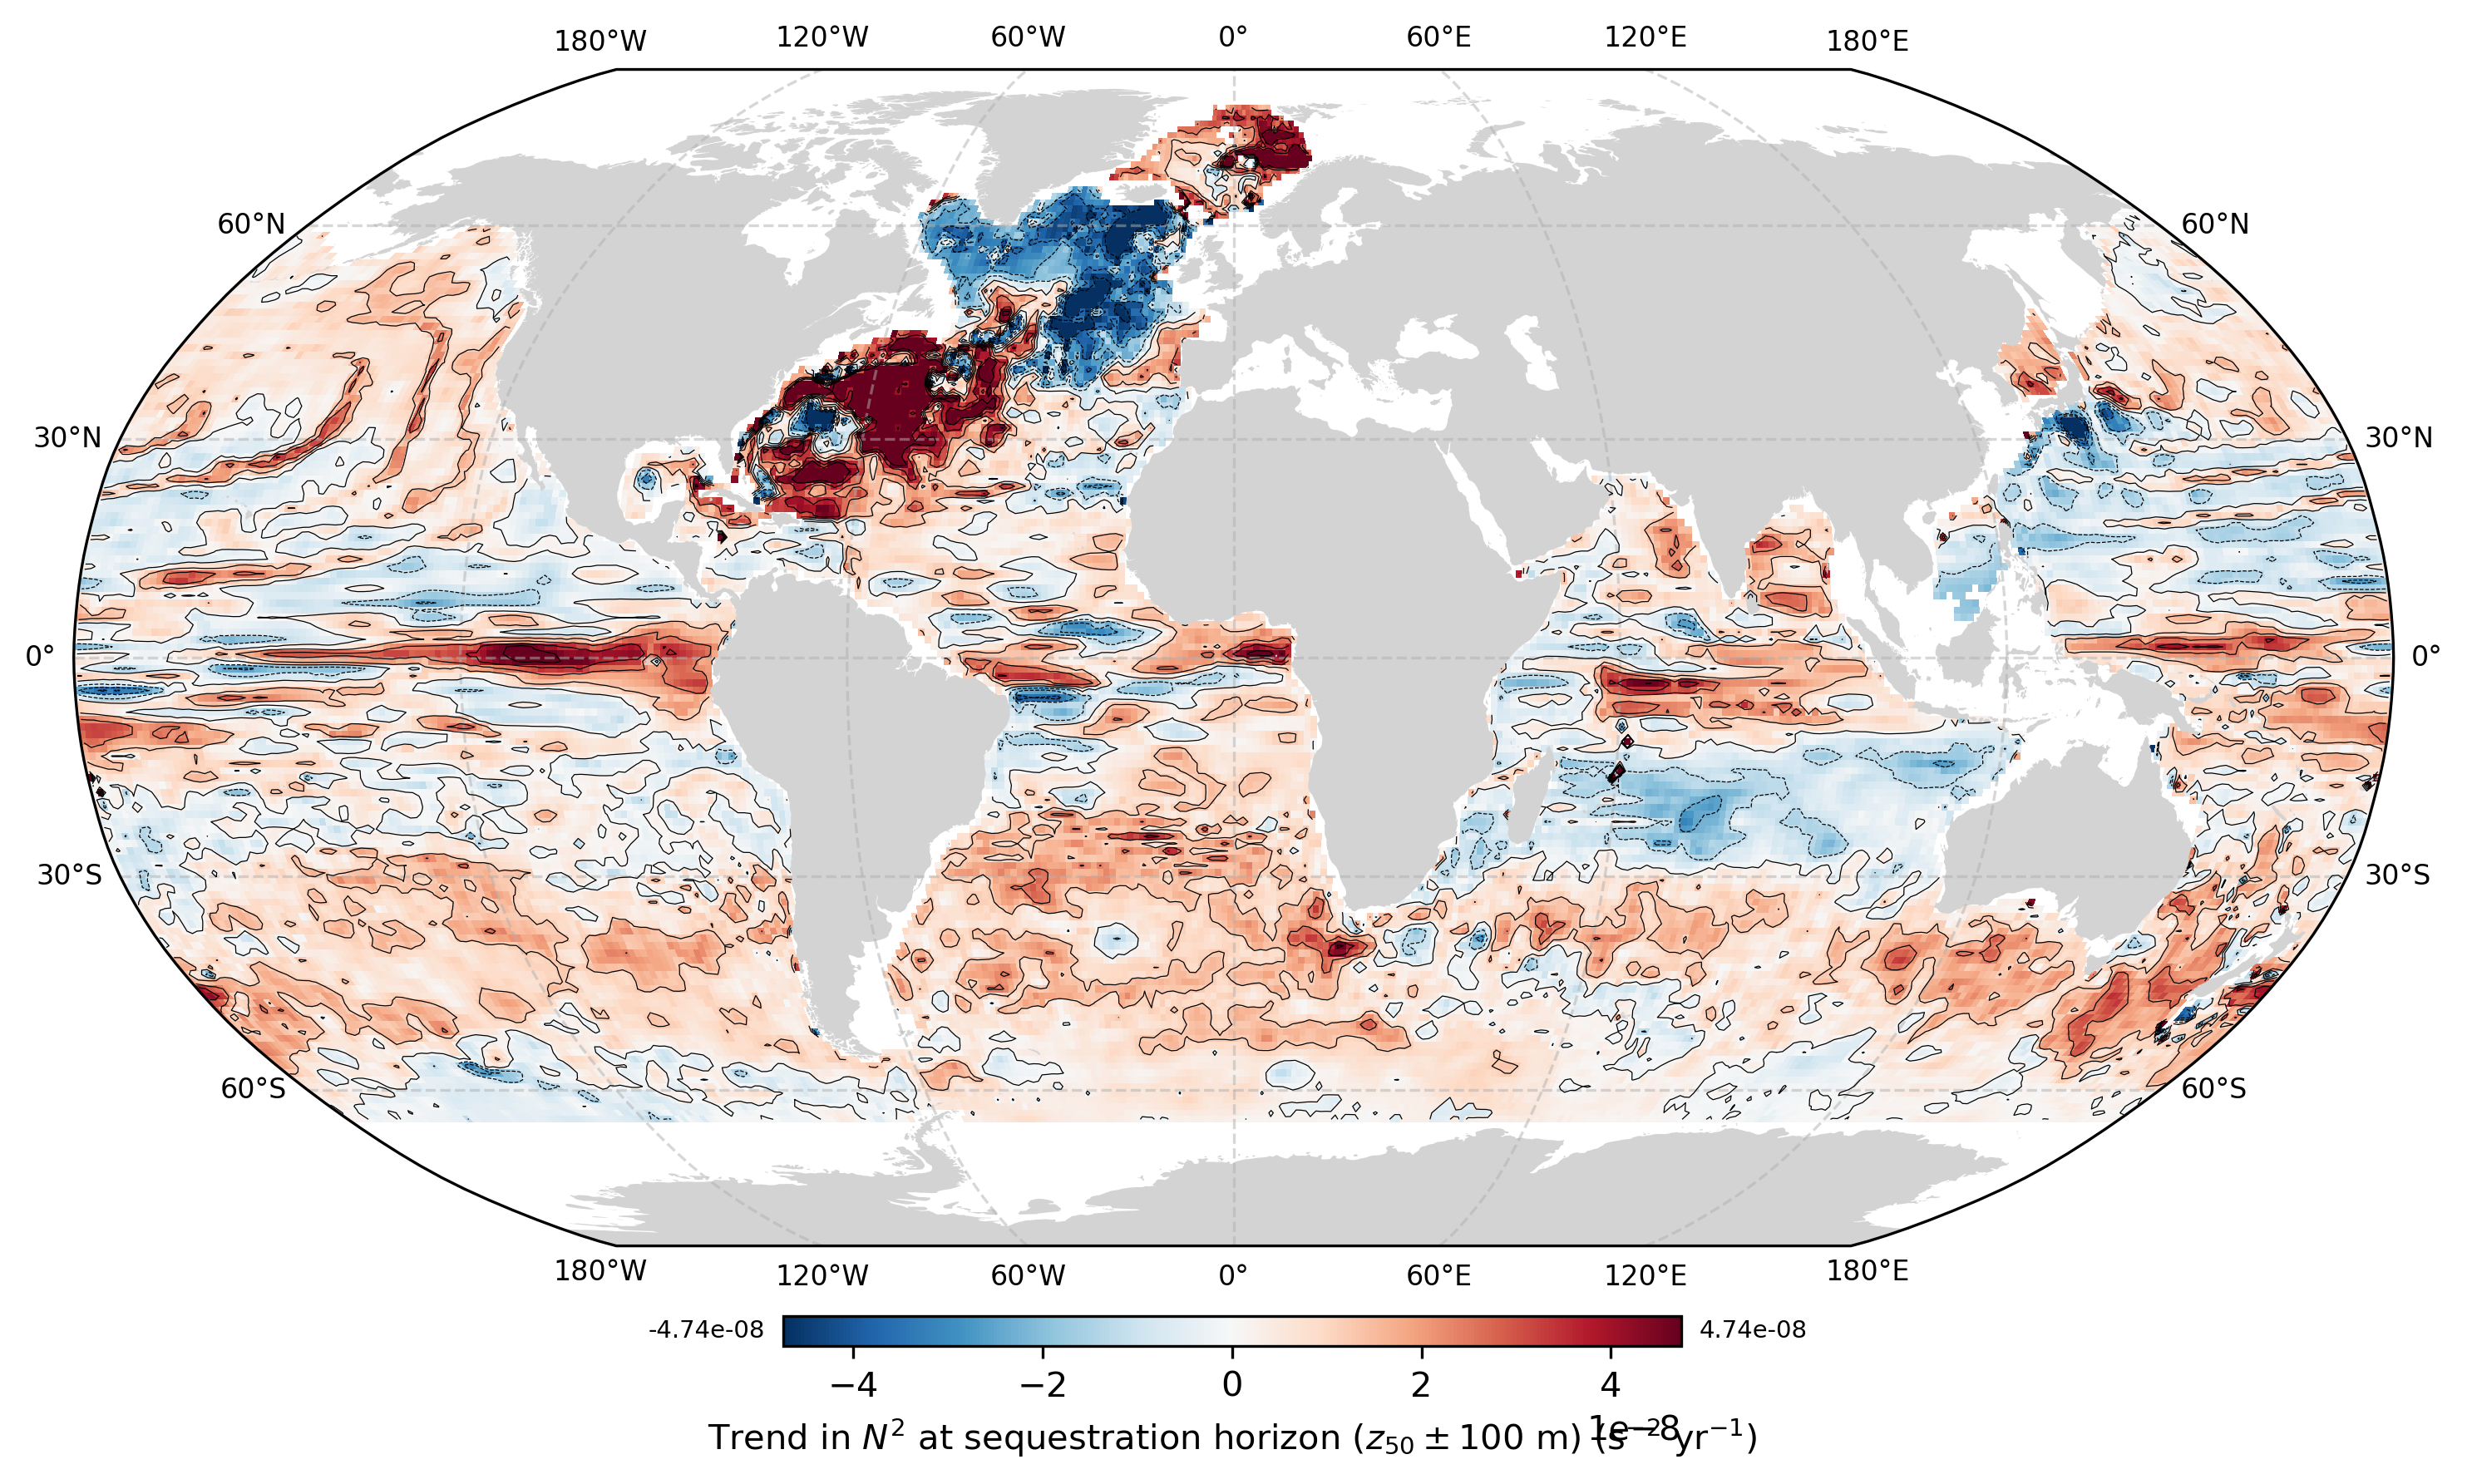

In [33]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.colors import TwoSlopeNorm
import matplotlib.ticker as mticker
import cartopy.mpl.ticker as cticker

# --- Define Mediterranean mask function ---
def mask_mediterranean(lat, lon):
    lat_min, lat_max = 30, 46
    lon_min, lon_max = -6, 37
    return (lat >= lat_min) & (lat <= lat_max) & (lon >= lon_min) & (lon <= lon_max)

# --- Extract coords ---
lon = slope_z50band['lon'].values
lat = slope_z50band['lat'].values
lon_2d, lat_2d = np.meshgrid(lon, lat)

# --- Data ---
data = slope_z50band.values  # trend in N^2 near z50 (s^-2 yr^-1)

# --- Optional: mask Mediterranean (to match your other maps) ---
med_mask = mask_mediterranean(lat_2d, lon_2d)
data = np.where(med_mask, np.nan, data)

# --- Robust symmetric color limits (good for tiny N² trends) ---
valid = np.isfinite(data)
vmin = np.nanpercentile(data[valid], 2)
vmax = np.nanpercentile(data[valid], 99)
lim = max(abs(vmin), abs(vmax))
vmin, vmax = -lim, lim

# --- Create figure ---
fig = plt.figure(figsize=(12, 8), dpi=300)
ax = fig.add_subplot(1, 1, 1, projection=ccrs.Robinson())
ax.set_global()

# Land
land_feature = cfeature.NaturalEarthFeature(
    'physical', 'land', '50m', edgecolor='none', facecolor='lightgrey'
)
ax.add_feature(land_feature)

# --- Gridlines with formatting ---
gl = ax.gridlines(draw_labels=True, alpha=0.5, linestyle='--')
gl.top_labels = True
gl.bottom_labels = True
gl.right_labels = True
gl.left_labels = True

gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
gl.ylocator = mticker.FixedLocator(np.arange(-90, 91, 30))

class CustomLongitudeFormatter(cticker.LongitudeFormatter):
    def __call__(self, lon, pos=None):
        if lon == 0:
            return "0°"
        elif lon < 0:
            return f"{abs(lon):g}°W"
        else:
            return f"{lon:g}°E"

gl.xformatter = CustomLongitudeFormatter()
gl.yformatter = cticker.LatitudeFormatter()

fig.canvas.draw()
for label in gl.xlabel_artists + gl.ylabel_artists:
    label.set_fontsize(8)

gl.xformatter._east_label = '180°E'

# --- Plot ---
norm = TwoSlopeNorm(vcenter=0, vmin=vmin, vmax=vmax)
im = ax.pcolormesh(
    lon_2d, lat_2d, data,
    transform=ccrs.PlateCarree(),
    cmap='RdBu_r',
    norm=norm
)

# Contours (optional)
levels = np.linspace(vmin, vmax, 9)
ax.contour(
    lon_2d, lat_2d, data,
    levels=levels,
    colors='black',
    linewidths=0.3,
    transform=ccrs.PlateCarree()
)

# --- Colorbar (match your style) ---
ax.set_title("")
cbar_ax = fig.add_axes([0.362, 0.15, 0.3, 0.015])
cbar = fig.colorbar(im, cax=cbar_ax, orientation='horizontal')
cbar.set_label(r"Trend in $N^2$ at sequestration horizon ($z_{50}\pm100$ m) (s$^{-2}$ yr$^{-1}$)")

# End labels (optional)
cbar_ax.text(-0.02, 0.5, f"{vmin:.2e}", va='center', ha='right',
             transform=cbar_ax.transAxes, fontsize=7)
cbar_ax.text(1.02, 0.5, f"{vmax:.2e}", va='center', ha='left',
             transform=cbar_ax.transAxes, fontsize=7)

# --- Save ---
fig.savefig('figs/N2_trend_z50pm100_map.png', bbox_inches='tight', dpi=300)
plt.show()
